In [1]:
import pandas as pd
import geopandas as gpd
import pyogrio

ruta_gdb = "../data/raw/DIVIPOLA_2026.gdb"
print(pyogrio.list_layers(ruta_gdb))

[['pdt_dpa_suelo_exp_urb' 'MultiPolygon']
 ['pdt_dpa_barrios_sectores' 'MultiPolygon']
 ['pdt_dpa_veredas' 'MultiPolygon']
 ['pdt_dpa_comunas' 'MultiPolygon']
 ['pdt_dpa_clasificacion_suelo' 'MultiPolygon']
 ['bcs_lim_perimetro_urbano' 'MultiPolygon']
 ['pdt_dpa_corregimientos' 'MultiPolygon']
 ['pdt_dpa_sectores_suelo_exp_urb' 'MultiPolygon']
 ['pdt_dpa_perimetro_municipal' 'MultiPolygon']
 ['T_1_DirtyAreas' 'MultiPolygon']
 ['T_1_PointErrors' 'Point']
 ['T_1_LineErrors' 'MultiLineString']
 ['T_1_PolyErrors' 'MultiPolygon']]


In [2]:
pd.set_option("display.max_rows", 100)

try:
    pob = pd.read_csv("../data/raw/poblacion_comunas.csv")
except UnicodeDecodeError:
    pob = pd.read_csv("../data/raw/poblacion_comunas.csv", encoding="latin-1")

print(pob.shape)
pob[["Descripción", "2018", "2019", "2020"]]

(41, 17)


,Descripción,2018,2019,2020
0,TOTAL CALI,2445281,2470747,2496346
1,Total Cabecera,2408653,2434110,2459698
2,Comuna 1,97382,100497,103620
3,Comuna 2,120577,122637,124669
4,Comuna 3,46759,46887,46990
5,Comuna 4,52433,52132,51806
6,Comuna 5,114842,115759,116608
7,Comuna 6,194894,196573,198137
8,Comuna 7,69793,69285,68739
9,Comuna 8,103034,103266,103445


In [3]:
pob = pob.rename(columns={"Descripción": "descripcion"})
pob["descripcion"] = pob["descripcion"].str.strip()

pob_com = pob[pob["descripcion"].str.startswith("Comuna")].copy()
pob_com["comuna"] = pob_com["descripcion"].str.extract(r"(\d+)", expand=False).astype(int)
pob_com = pob_com[["comuna", "2020"]].rename(columns={"2020": "poblacion_2020"})

print(pob_com.shape)                      # debe dar (22, 2)
print(pob_com["poblacion_2020"].sum())    # debe dar 2424984

(22, 2)
2424984


In [4]:
df = pd.read_csv("../data/clean/escenarios_deportivos_limpio.csv")
urbano = df[df["zona"] == "Urbana"]

por_comuna = (
    urbano.groupby("comuna")
    .agg(escenarios=("escenario", "count"),
         instalaciones=("total_instalaciones", "sum"))
    .reset_index()
    .merge(pob_com, on="comuna", how="left")
)

por_comuna["esc_por_10k"] = (
    por_comuna["escenarios"] / por_comuna["poblacion_2020"] * 10000
).round(2)

print("Comunas sin población:", por_comuna["poblacion_2020"].isna().sum())  # debe ser 0
por_comuna.sort_values("esc_por_10k", ascending=False)


Comunas sin población: 0


,comuna,escenarios,instalaciones,poblacion_2020,esc_por_10k
6,7,42,85,68739,6.11
3,4,21,46,51806,4.05
20,21,42,83,121440,3.46
4,5,40,110,116608,3.43
10,11,37,89,110302,3.35
9,10,34,95,113040,3.01
5,6,56,152,198137,2.83
8,9,11,13,43330,2.54
12,13,44,98,181084,2.43
13,14,44,102,181093,2.43


In [5]:
comunas = gpd.read_file(ruta_gdb, layer="pdt_dpa_comunas")
print(comunas.crs)
print(len(comunas))
print(comunas.columns.tolist())
comunas.drop(columns="geometry").head(25)

EPSG:6249
22
['ComCodigo', 'ComNombre', 'ComAcuerdo', 'Shape_Length', 'Shape_Area', 'ComConsul', 'geometry']


,ComCodigo,ComNombre,ComAcuerdo,Shape_Length,Shape_Area,ComConsul
0,01,Comuna 01,https://idesc.cali.gov.co/download/acuerdos/20...,15293.839028,2.941386e+06,https://saul.cali.gov.co/tramites/concepto-div...
1,02,Comuna 02,https://idesc.cali.gov.co/download/acuerdos/20...,27827.779639,1.085957e+07,https://saul.cali.gov.co/tramites/concepto-div...
2,03,Comuna 03,https://idesc.cali.gov.co/download/acuerdos/20...,11008.793387,3.704254e+06,https://saul.cali.gov.co/tramites/concepto-div...
3,04,Comuna 04,https://idesc.cali.gov.co/download/acuerdos/20...,11374.767818,4.522666e+06,https://saul.cali.gov.co/tramites/concepto-div...
4,05,Comuna 05,https://idesc.cali.gov.co/download/acuerdos/20...,8438.864021,4.199642e+06,https://saul.cali.gov.co/tramites/concepto-div...
5,06,Comuna 06,https://idesc.cali.gov.co/download/acuerdos/20...,12758.419580,5.380641e+06,https://saul.cali.gov.co/tramites/concepto-div...
6,07,Comuna 07,https://idesc.cali.gov.co/download/acuerdos/20...,12552.549878,5.248185e+06,https://saul.cali.gov.co/tramites/concepto-div...
7,08,Comuna 08,https://idesc.cali.gov.co/download/acuerdos/20...,12187.367496,5.270329e+06,https://saul.cali.gov.co/tramites/concepto-div...
8,09,Comuna 09,https://idesc.cali.gov.co/download/acuerdos/20...,7988.159624,2.901208e+06,https://saul.cali.gov.co/tramites/concepto-div...
9,10,Comuna 10,https://idesc.cali.gov.co/download/acuerdos/20...,9404.676505,4.297756e+06,https://saul.cali.gov.co/tramites/concepto-div...


In [6]:
comunas = gpd.read_file(ruta_gdb, layer="pdt_dpa_comunas")
comunas["comuna"] = comunas["ComCodigo"].astype(str).str.extract(r"(\d+)", expand=False).astype(int)

print(sorted(comunas["comuna"].tolist()))        # debe ser 1 a 22
print(comunas[["ComCodigo", "ComNombre", "ComAcuerdo"]].head(25))

mapa = comunas.merge(por_comuna, on="comuna", how="left")
print("Comunas sin dato:", mapa["esc_por_10k"].isna().sum())   # debe ser 0

por_comuna.to_csv("../data/clean/escenarios_por_comuna.csv", index=False)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]
   ComCodigo  ComNombre                                         ComAcuerdo
0         01  Comuna 01  https://idesc.cali.gov.co/download/acuerdos/20...
1         02  Comuna 02  https://idesc.cali.gov.co/download/acuerdos/20...
2         03  Comuna 03  https://idesc.cali.gov.co/download/acuerdos/20...
3         04  Comuna 04  https://idesc.cali.gov.co/download/acuerdos/20...
4         05  Comuna 05  https://idesc.cali.gov.co/download/acuerdos/20...
5         06  Comuna 06  https://idesc.cali.gov.co/download/acuerdos/20...
6         07  Comuna 07  https://idesc.cali.gov.co/download/acuerdos/20...
7         08  Comuna 08  https://idesc.cali.gov.co/download/acuerdos/20...
8         09  Comuna 09  https://idesc.cali.gov.co/download/acuerdos/20...
9         10  Comuna 10  https://idesc.cali.gov.co/download/acuerdos/20...
10        11  Comuna 11  https://idesc.cali.gov.co/download/acuerdos/20...
11        12  Comuna

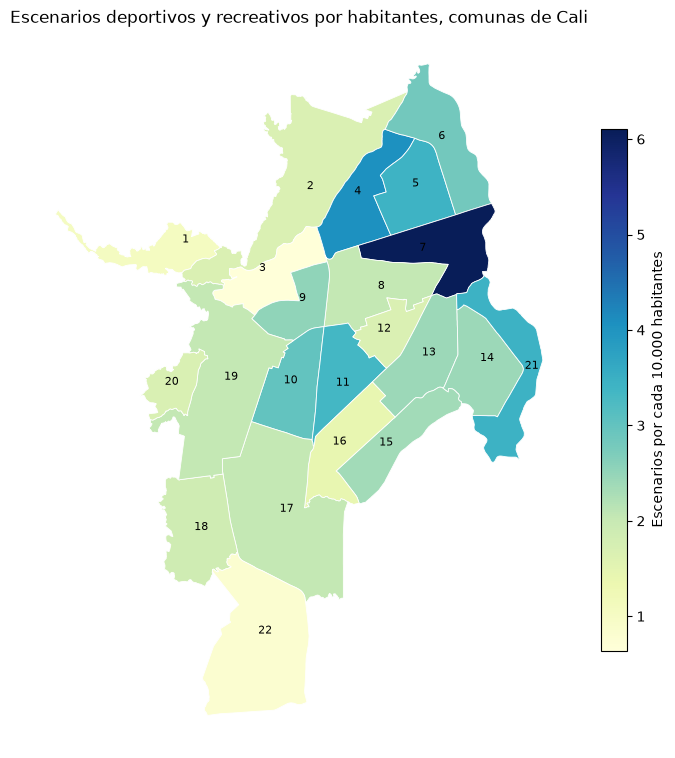

In [7]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 9))
mapa.plot(column="esc_por_10k", cmap="YlGnBu", edgecolor="white", linewidth=0.6,
          legend=True, legend_kwds={"label": "Escenarios por cada 10.000 habitantes", "shrink": 0.6},
          ax=ax)

for _, fila in mapa.iterrows():
    p = fila.geometry.representative_point()
    ax.annotate(str(fila["comuna"]), (p.x, p.y), ha="center", fontsize=8, color="black")

ax.set_title("Escenarios deportivos y recreativos por habitantes, comunas de Cali")
ax.set_axis_off()
plt.tight_layout()
plt.savefig("../reports/figures/mapa_escenarios_por_10k.png", dpi=150)
plt.show()

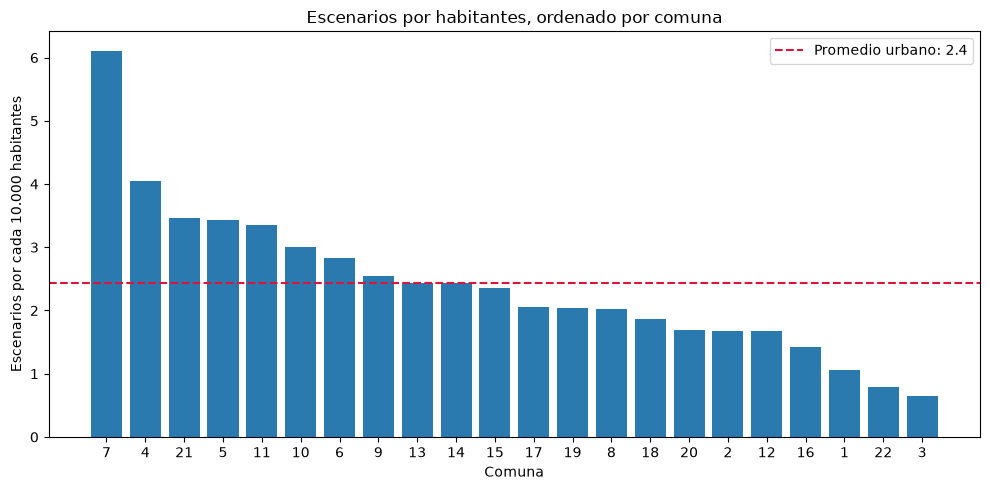

In [8]:
orden = por_comuna.sort_values("esc_por_10k", ascending=False)
promedio = por_comuna["escenarios"].sum() / por_comuna["poblacion_2020"].sum() * 10000

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(orden["comuna"].astype(str), orden["esc_por_10k"], color="#2a7ab0")
ax.axhline(promedio, color="crimson", linestyle="--", label=f"Promedio urbano: {promedio:.1f}")
ax.set_xlabel("Comuna")
ax.set_ylabel("Escenarios por cada 10.000 habitantes")
ax.set_title("Escenarios por habitantes, ordenado por comuna")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/ranking_esc_por_10k.png", dpi=150)
plt.show()

In [9]:
por_comuna["inst_por_10k"] = (por_comuna["instalaciones"] / por_comuna["poblacion_2020"] * 10000).round(2)

ranking = por_comuna[["comuna", "escenarios", "instalaciones", "poblacion_2020",
                      "esc_por_10k", "inst_por_10k"]].copy()
ranking["rank_esc"] = ranking["esc_por_10k"].rank(ascending=False).astype(int)
ranking["rank_inst"] = ranking["inst_por_10k"].rank(ascending=False).astype(int)

print(ranking[["esc_por_10k", "inst_por_10k"]].corr(method="spearman"))
ranking.sort_values("rank_esc")

              esc_por_10k  inst_por_10k
esc_por_10k      1.000000      0.789607
inst_por_10k     0.789607      1.000000


,comuna,escenarios,instalaciones,poblacion_2020,esc_por_10k,inst_por_10k,rank_esc,rank_inst
6,7,42,85,68739,6.11,12.37,1,1
3,4,21,46,51806,4.05,8.88,2,3
20,21,42,83,121440,3.46,6.83,3,7
4,5,40,110,116608,3.43,9.43,4,2
10,11,37,89,110302,3.35,8.07,5,5
9,10,34,95,113040,3.01,8.40,6,4
5,6,56,152,198137,2.83,7.67,7,6
8,9,11,13,43330,2.54,3.00,8,20
13,14,44,102,181093,2.43,5.63,9,11
12,13,44,98,181084,2.43,5.41,9,12


In [10]:
ranking["cambio_posicion"] = ranking["rank_esc"] - ranking["rank_inst"]   # positivo = sube con instalaciones

ranking.sort_values("rank_esc")[["comuna", "escenarios", "instalaciones",
                                 "esc_por_10k", "inst_por_10k",
                                 "rank_esc", "rank_inst", "cambio_posicion"]]

,comuna,escenarios,instalaciones,esc_por_10k,inst_por_10k,rank_esc,rank_inst,cambio_posicion
6,7,42,85,6.11,12.37,1,1,0
3,4,21,46,4.05,8.88,2,3,-1
20,21,42,83,3.46,6.83,3,7,-4
4,5,40,110,3.43,9.43,4,2,2
10,11,37,89,3.35,8.07,5,5,0
9,10,34,95,3.01,8.40,6,4,2
5,6,56,152,2.83,7.67,7,6,1
8,9,11,13,2.54,3.00,8,20,-12
13,14,44,102,2.43,5.63,9,11,-2
12,13,44,98,2.43,5.41,9,12,-3


In [11]:
ranking.to_csv("../data/clean/ranking_comunas.csv", index=False)

In [12]:
corr = gpd.read_file(ruta_gdb, layer="pdt_dpa_corregimientos")
print(corr.crs, len(corr))
print(corr.columns.tolist())
corr.drop(columns="geometry")

EPSG:6249 15
['CorrCod', 'CorrNombre', 'CorrAcuer1', 'CorrAcuer2', 'Shape_Length', 'Shape_Area', 'CorrConsul', 'geometry']


,CorrCod,CorrNombre,CorrAcuer1,CorrAcuer2,Shape_Length,Shape_Area,CorrConsul
0,51,Navarro,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,44116.136285,2.051539e+07,https://saul.cali.gov.co/tramites/concepto-div...
1,52,El Hormiguero,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,47522.754759,5.672201e+07,https://saul.cali.gov.co/tramites/concepto-div...
2,53,Pance,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,65504.121681,1.068880e+08,https://saul.cali.gov.co/tramites/concepto-div...
3,54,La Buitrera,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,36056.583310,3.032690e+07,https://saul.cali.gov.co/tramites/concepto-div...
4,55,Villacarmelo,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,31694.764481,3.250311e+07,https://saul.cali.gov.co/tramites/concepto-div...
5,56,Los Andes,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,56214.285595,6.723597e+07,https://saul.cali.gov.co/tramites/concepto-div...
6,57,Pichinde,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,31240.083844,1.555836e+07,https://saul.cali.gov.co/tramites/concepto-div...
7,58,La Leonera,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,29068.660877,1.677749e+07,https://saul.cali.gov.co/tramites/concepto-div...
8,59,Felidia,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,40488.614074,2.566373e+07,https://saul.cali.gov.co/tramites/concepto-div...
9,60,El Saladito,https://idesc.cali.gov.co/download/acuerdos/co...,https://idesc.cali.gov.co/download/acuerdos/20...,38828.720508,1.461879e+07,https://saul.cali.gov.co/tramites/concepto-div...


In [13]:
import unicodedata, re

def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z0-9]", "", s)

# Capa de corregimientos
corr = gpd.read_file(ruta_gdb, layer="pdt_dpa_corregimientos")
corr["codigo"] = corr["CorrCod"].astype(str).str.extract(r"(\d+)", expand=False).astype(int)
corr["clave"] = corr["CorrNombre"].map(norm)

# Población: filas que vienen después de "Total Corregimientos"
try:
    pob = pd.read_csv("../data/raw/poblacion_comunas.csv")
except UnicodeDecodeError:
    pob = pd.read_csv("../data/raw/poblacion_comunas.csv", encoding="latin-1")

pob = pob.rename(columns={"Descripción": "descripcion"})
pob["descripcion"] = pob["descripcion"].str.strip()
inicio = pob.index[pob["descripcion"] == "Total Corregimientos"][0]
pob_corr = pob.loc[inicio + 1:, ["descripcion", "2020"]].rename(columns={"2020": "poblacion_2020"})
pob_corr["clave"] = pob_corr["descripcion"].map(norm)

# Tabla de equivalencias nombre <-> código
tabla = pob_corr.merge(corr[["codigo", "CorrNombre", "clave"]], on="clave", how="left")
print("Filas:", len(tabla), "| sin código:", tabla["codigo"].isna().sum())   # esperado: 15 y 0
print(tabla[tabla["codigo"].isna()])

Filas: 15 | sin código: 0
Empty DataFrame
Columns: [descripcion, poblacion_2020, clave, codigo, CorrNombre]
Index: []


In [14]:
df = pd.read_csv("../data/clean/escenarios_deportivos_limpio.csv")
rural = df[df["zona"] == "Rural"]

esc = (rural.groupby("comuna")
       .agg(escenarios=("escenario", "count"), instalaciones=("total_instalaciones", "sum"))
       .reset_index().rename(columns={"comuna": "codigo"}))

rural_tab = tabla.merge(esc, on="codigo", how="left")
rural_tab[["escenarios", "instalaciones"]] = rural_tab[["escenarios", "instalaciones"]].fillna(0).astype(int)
rural_tab["esc_por_10k"] = (rural_tab["escenarios"] / rural_tab["poblacion_2020"] * 10000).round(2)

print("Escenarios rurales:", rural_tab["escenarios"].sum())     # esperado: 25
print("Corregimientos sin escenarios:", (rural_tab["escenarios"] == 0).sum())
print("Promedio rural:", round(rural_tab["escenarios"].sum() / rural_tab["poblacion_2020"].sum() * 10000, 2))

rural_tab.to_csv("../data/clean/escenarios_por_corregimiento.csv", index=False)
rural_tab[["codigo", "descripcion", "escenarios", "instalaciones",
           "poblacion_2020", "esc_por_10k"]].sort_values("esc_por_10k", ascending=False)

Escenarios rurales: 25
Corregimientos sin escenarios: 0
Promedio rural: 6.82


,codigo,descripcion,escenarios,instalaciones,poblacion_2020,esc_por_10k
0,51,Navarro,2,4,778,25.71
7,58,La Leonera,1,1,418,23.92
12,63,La Paz,1,0,516,19.38
6,57,Pichinde,1,1,581,17.21
2,53,Pance,2,1,1287,15.54
9,60,El Saladito,1,1,752,13.30
4,55,Villacarmelo,1,2,818,12.22
11,62,La Castilla,1,0,869,11.51
10,61,La Elvira,1,0,945,10.58
5,56,Los Andes,5,4,4830,10.35


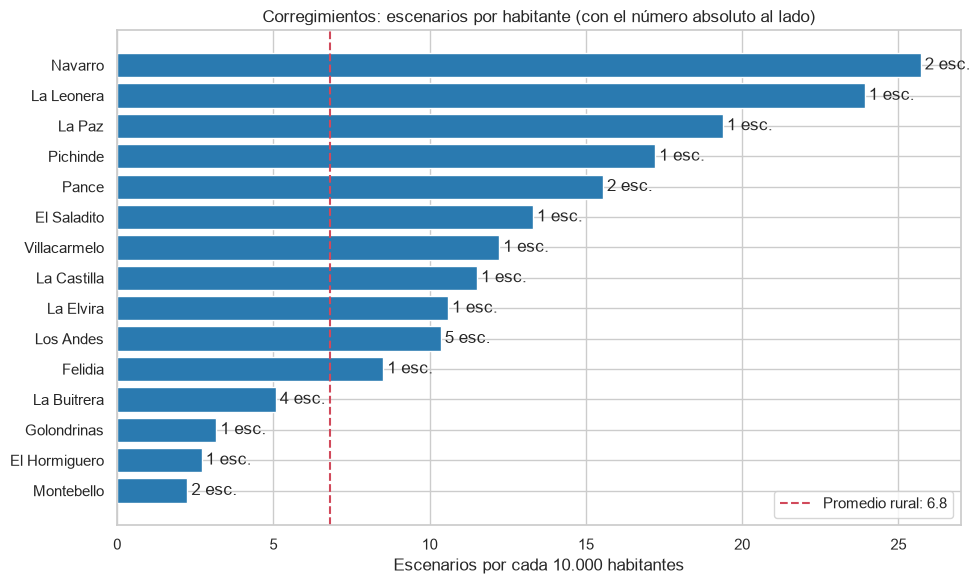

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
AZUL, ROJO = "#2a7ab0", "#d1495b"

rural_tab = pd.read_csv("../data/clean/escenarios_por_corregimiento.csv")
orden = rural_tab.sort_values("esc_por_10k", ascending=False)
prom_rural = rural_tab["escenarios"].sum() / rural_tab["poblacion_2020"].sum() * 10000

fig, ax = plt.subplots(figsize=(10, 6))
barras = ax.barh(orden["descripcion"], orden["esc_por_10k"], color=AZUL)
ax.bar_label(barras, labels=[f"{e} esc." for e in orden["escenarios"]], padding=3)
ax.axvline(prom_rural, color=ROJO, linestyle="--", label=f"Promedio rural: {prom_rural:.1f}")
ax.invert_yaxis()
ax.set_xlabel("Escenarios por cada 10.000 habitantes")
ax.set_title("Corregimientos: escenarios por habitante (con el número absoluto al lado)")
ax.legend()
plt.tight_layout()
plt.savefig("../reports/figures/corregimientos_esc_por_10k.png", dpi=150)
plt.show()

In [16]:
import pandas as pd

por_comuna = pd.read_csv("../data/clean/escenarios_por_comuna.csv")
rural_tab = pd.read_csv("../data/clean/escenarios_por_corregimiento.csv")

resumen = pd.DataFrame({
    "zona": ["Urbana", "Rural"],
    "escenarios": [por_comuna["escenarios"].sum(), rural_tab["escenarios"].sum()],
    "instalaciones": [por_comuna["instalaciones"].sum(), rural_tab["instalaciones"].sum()],
    "poblacion": [por_comuna["poblacion_2020"].sum(), rural_tab["poblacion_2020"].sum()],
})
resumen["esc_por_10k"] = (resumen["escenarios"] / resumen["poblacion"] * 10000).round(2)
resumen["inst_por_10k"] = (resumen["instalaciones"] / resumen["poblacion"] * 10000).round(2)
resumen["inst_por_escenario"] = (resumen["instalaciones"] / resumen["escenarios"]).round(2)
resumen

,zona,escenarios,instalaciones,poblacion,esc_por_10k,inst_por_10k,inst_por_escenario
0,Urbana,592,1432,2424984,2.44,5.91,2.42
1,Rural,25,23,36649,6.82,6.28,0.92


In [17]:
resumen.to_csv("../data/clean/resumen_urbano_rural.csv", index=False)